### Introducción a los biopotenciales y adquisición de señales ECG y EMG

##### Presentado por: Alma Olea Barbosa - Lauren Cordero Ramos 

##### Semestre: 2026-2                                     Laboratorio Bioseñales

1- Esquema de las etapas de registros de biopotenciales - Descripción de los componentes de los equipos de adquisición

![Colorful Simple 8 Step Brainstrom (1).png](<attachment:Colorful Simple 8 Step Brainstrom (1).png>)
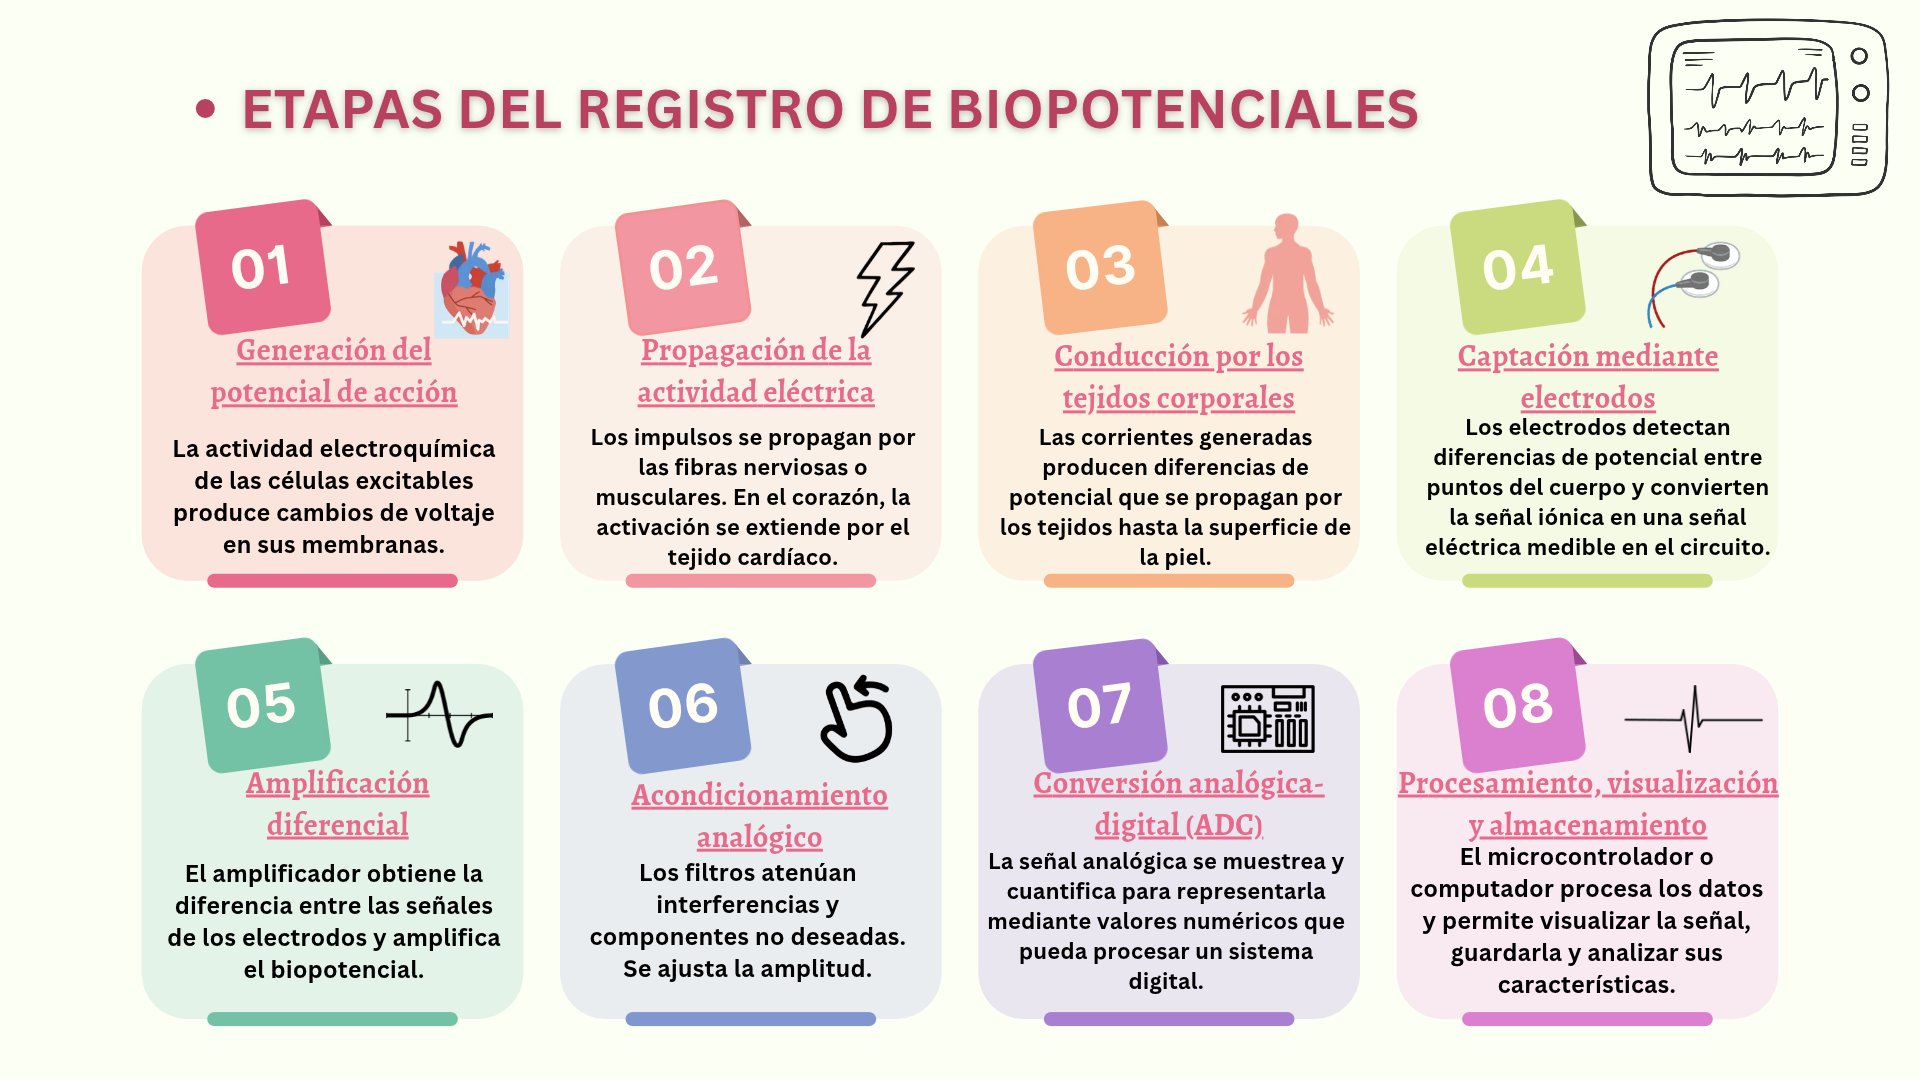

Componentes del equipo de adquisición: 

- *Electrodos y cables*: Captan las diferencias de potencial del cuerpo y conducen la señal hacia el circuito. En esta práctica se utilizan para los registros ECG y EMG.

- *Etapa de entrada y amplificador diferencial*: Recibe las señales de los electrodos, amplifica su diferencia y ayuda a reducir las interferencias de modo común. Una alta impedancia de entrada permite no cargar excesivamente la señal biológica.

- *Circuito de acondicionamiento*: Incluye filtros analógicos y otras etapas que ajustan la señal antes de la conversión digital. Los filtros utilizados dependen del tipo de biopotencial y del objetivo de la medición.

- *Convertidor analógico-digital (ADC)*: Convierte la señal analógica en datos digitales. En el montaje descrito por la guía, esta función la realiza el ADC integrado en el microcontrolador de la placa Arduino UNO.

- *Microcontrolador, computador y software*: El microcontrolador gestiona la lectura y transmisión de los datos. El computador y el software permiten visualizar, guardar y procesar las señales adquiridas.

- *Fuente de alimentación*: Proporciona la energía eléctrica necesaria para el funcionamiento de los circuitos. En equipos conectados a una persona, el diseño de alimentación y aislamiento debe cumplir los requisitos de seguridad eléctrica aplicables.

2- Principales fuentes de ruido en el registro de biopotenciales - Análisis


| Fuente | Origen | Naturaleza | Control / eliminación |
|---|---|---|---|
| Red eléctrica (60 Hz) | Acoplamiento capacitivo/inductivo | **Estática** | CMRR alto, DRL, blindaje, cables trenzados, batería, notch |
| Offset DC (semicelda) | Reacción electroquímica del electrodo | **Estática** | Ag/AgCl, mismo lote, pasa-altos |
| Ruido térmico y electrónico | Resistencias y amplificador | **Estática** | Bajo ruido, limitar ancho de banda, promediado |
| Cuantización y aliasing | Resolución del ADC (10 bits) | **Estática** | Antialiasing, fs adecuada, ajustar ganancia |
| Artefacto de movimiento | Deformación de piel y cables | **Variante** | Buena fijación, gel, electrodos activos, pasa-altos |
| Impedancia piel-electrodo | Sudor, gel seco, grasa | **Variante** | Limpieza, abrasión, gel, alta impedancia de entrada |
| Deriva de línea base | Respiración, movimiento | **Variante** | Pasa-altos (~0.5 Hz ECG), detrending |
| Ruido muscular en ECG | Músculos vecinos (20–500 Hz) | **Variante** | Relajación, pasa-bajos, promediado |
| Crosstalk entre bioseñales | ECG en sEMG, músculos vecinos | **Variante** | Ubicación correcta, pasa-altos (~20 Hz), ICA |
| Interferencia EM / RF | Celulares, electrobisturí, fuentes conmutadas | **Variante** | Blindaje, filtros RFI, alejar fuentes |



3-  Acoplamiento piel-electrodo - Análisis

- _Problemática_. La piel, en particular su capa córnea (células muertas y secas), tiene una impedancia muy alta, de decenas a cientos de kΩ si no se prepara. A esto se suman el potencial de semicelda del electrodo, que genera un offset DC, y la doble capa electroquímica, cuya impedancia depende de la frecuencia. Si las impedancias de los electrodos no son iguales, el ruido de modo común (60 Hz) se convierte en ruido diferencial. Además, la interfaz cambia con el sudor, el secado del gel y el movimiento, lo que produce deriva de línea base y artefactos.

- _Estrategias_. Se limpia, rasura y abrade suavemente la piel, y se usa gel electrolítico y electrodos de Ag/AgCl, que son estables y no polarizables. Se fijan bien los electrodos y los cables para reducir el movimiento. También se emplean electrodos activos, amplificadores con alta impedancia de entrada y CMRR alto, y un circuito de pierna derecha (DRL). Antes de registrar se verifica que la impedancia sea baja (idealmente menor a 5-10 kΩ) y similar entre electrodos.

- _¿Por qué es la etapa más crítica?_ Es el primer eslabón de la cadena, por lo que cualquier error se propaga a las etapas siguientes y no se puede corregir después. Las señales son muy pequeñas (ECG ≈ 1 mV, sEMG 50 µV-5 mV, EEG 10-100 µV), así que el offset y los artefactos de esta interfaz son comparables o mayores que la señal útil. Es además la fuente dominante de ruido y es variable e impredecible. El filtrado posterior no puede eliminarlo del todo, porque se superpone en frecuencia con la señal y puede distorsionarla. Por eso una buena interfaz reduce el ruido desde el origen.

4- Análisis de la variabilidad de la frecuencia cardiaca

4.1- Picos R con Neurokit y Detectors

In [11]:
#%pip install numpy pandas matplotlib scipy scikit-learn PyWavelets neurokit2 py-ecg-detectors

In [ ]:
import numpy as np, pandas as pd, neurokit2 as nk
import matplotlib.pyplot as plt
from ecgdetectors import Detectors

ruta = r"C:\Users\usuario\Downloads\SerialBiosenales\SerialBiosenales EKG.txt"
datos = np.loadtxt(ruta)

if datos.ndim == 2:              # 2 columnas: tiempo y señal
    t, ecg = datos[:, 0], datos[:, 1]
    fs = 1 / np.median(np.diff(t))
else:                            # 1 columna: solo la señal
    ecg = datos
    fs = 100                     # delay(10) en el Arduino -> ~100 Hz

ecg = ecg - np.mean(ecg)
print(f"Muestras: {len(ecg)} | fs = {fs:.1f} Hz | duración = {len(ecg)/fs:.1f} s")

In [ ]:
ecg_clean = nk.ecg_clean(ecg, sampling_rate=fs, method="neurokit")
picos = {}

# NeuroKit
for m in ["neurokit", "pantompkins1985", "hamilton2002", "christov2004", "engzeemod2012"]:
    try:
        _, info = nk.ecg_peaks(ecg_clean, sampling_rate=fs, method=m)
        picos[f"NK-{m}"] = np.array(info["ECG_R_Peaks"])
    except Exception as e:
        print(f"NK-{m}: omitido ({type(e).__name__}: {e})")

# Detectors (usan la señal cruda)
det = Detectors(fs)
for nombre, f in {"DET-pan_tompkins": det.pan_tompkins_detector,
                  "DET-hamilton": det.hamilton_detector,
                  "DET-christov": det.christov_detector,
                  "DET-engzee": det.engzee_detector,
                  "DET-two_average": det.two_average_detector,
                  "DET-swt": det.swt_detector}.items():
    try:
        picos[nombre] = np.array(f(ecg))
    except Exception as e:
        print(f"{nombre}: omitido, no soporta fs = {fs:.0f} Hz ({type(e).__name__})")

# Alinear todos los picos al máximo local (algunos detectores marcan con desfase)
def refinar(p, sig, ventana):
    out = []
    for i in p:
        a, b = max(0, i-ventana), min(len(sig), i+ventana+1)
        out.append(a + int(np.argmax(sig[a:b])))
    return np.unique(out)

ecg_ref = nk.signal_filter(ecg, sampling_rate=fs, lowcut=5, highcut=20, method="butterworth", order=2)
picos = {k: refinar(v, ecg_ref, int(0.10*fs)) for k, v in picos.items()}

In [ ]:
filas = []
for nombre, p in picos.items():
    if len(p) < 2:
        filas.append({"Algoritmo": nombre, "N picos": len(p), "FC media (lpm)": None,
                      "RR mín (s)": None, "RR máx (s)": None})
        continue
    rr = np.diff(p) / fs
    filas.append({"Algoritmo": nombre, "N picos": len(p),
                  "FC media (lpm)": round(60 / rr.mean(), 1),
                  "RR mín (s)": round(rr.min(), 2),
                  "RR máx (s)": round(rr.max(), 2)})
display(pd.DataFrame(filas))

In [ ]:
# Gráficas de picos R: NeuroKit
t = np.arange(len(ecg)) / fs
nk_picos  = {k: v for k, v in picos.items() if k.startswith("NK-")}
det_picos = {k: v for k, v in picos.items() if k.startswith("DET-")}

def graficar(grupo, titulo, color):
    fig, axs = plt.subplots(len(grupo), 1, figsize=(14, 2.2*len(grupo)), sharex=True)
    for ax, (nombre, p) in zip(np.atleast_1d(axs), grupo.items()):
        ax.plot(t, ecg, color="gray", lw=0.8)
        ax.plot(t[p], ecg[p], "o", color=color, ms=5)
        ax.set_ylabel(f"{nombre}\n({len(p)} picos)", rotation=0, ha="right", va="center", fontsize=8)
        ax.set_yticks([])
    np.atleast_1d(axs)[-1].set_xlabel("Tiempo (s)")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

graficar(nk_picos, "Picos R detectados con NeuroKit", "tab:blue")

In [ ]:
# Gráficas de picos R: Detectors
graficar(det_picos, "Picos R detectados con Detectors", "tab:red")

In [ ]:
# Comparación directa: el mismo algoritmo (Pan-Tompkins) en ambas librerías
plt.figure(figsize=(14, 4))
plt.plot(t, ecg, color="gray", lw=0.8, label="ECG")
p1, p2 = picos["NK-pantompkins1985"], picos["DET-pan_tompkins"]   # requiere que ambos existan
plt.plot(t[p1], ecg[p1], "o", color="tab:blue", ms=9, mfc="none", label=f"NeuroKit (Pan-Tompkins) - {len(p1)} picos")
plt.plot(t[p2], ecg[p2], "x", color="tab:red", ms=7, label=f"Detectors (Pan-Tompkins) - {len(p2)} picos")
plt.xlabel("Tiempo (s)"); plt.legend(loc="upper right", fontsize=8)
plt.title("Pan-Tompkins: NeuroKit vs Detectors")
plt.show()

4.2- Cálculo del HRV

4.3- Implementación de función de hryanalysis

5- Aplicaciones clínicas del ECG y EMG

6- Conclusiones

FALTA AGREGAR MÁS

- La calidad de un registro de biopotenciales depende de toda la cadena de adquisición (electrodos, amplificador diferencial, acondicionamiento, ADC y software), porque cada etapa puede añadir ruido o limitar la información. En esta práctica, el ADC de 10 bits del Arduino UNO limita la resolución, por lo que hay que ajustar la ganancia y la frecuencia de muestreo a la señal.

- Las fuentes de ruido se pueden separar según su comportamiento en el tiempo. Las estáticas (red de 60 Hz, offset DC, ruido térmico y cuantización) se controlan sobre todo con el diseño del hardware y con filtrado. Las variantes (movimiento, impedancia, deriva, ruido muscular y crosstalk) dependen de la técnica del operador y del sujeto, y por eso son más difíciles de eliminar.

- El acoplamiento piel-electrodo es la etapa más crítica porque es el primer eslabón de la cadena y la fuente dominante de ruido, mientras que las señales son de microvoltios a milivoltios. Una buena preparación de la piel, electrodos de Ag/AgCl y una fijación correcta reducen el ruido en el origen, algo que el filtrado posterior no logra del todo.

7- Referencias bibliográficas

- Kligfield P, Gettes LS, Bailey JJ, et al. Recommendations for the standardization and interpretation of the electrocardiogram. Part I: The electrocardiogram and its technology. Circulation. 2007;115(10):1306-1324. 

- Huigen E, Peper A, Grimbergen CA. Investigation into the origin of the noise of surface electrodes. Med Biol Eng Comput. 2002;40(3):332-338. 

- Chi YM, Jung TP, Cauwenberghs G. Dry-contact and noncontact biopotential electrodes: methodological review. IEEE Rev Biomed Eng. 2010;3:106-119.

- Merletti R, Muceli S. Tutorial. Surface EMG detection in space and time: best practices. J Electromyogr Kinesiol. 2019;49:102363. 

- Searle A, Kirkup L. A direct comparison of wet, dry and insulating bioelectric recording electrodes. Physiol Meas. 2000;21(2):271-283.